<a href="https://colab.research.google.com/github/saturnsz/Karhutla-2026-machine-learning-/blob/main/Karhutla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, cohen_kappa_score, mean_squared_error, roc_auc_score
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
print("1. Membaca dan Menyiapkan Data...")
df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')

1. Membaca dan Menyiapkan Data...


In [3]:
df_kalimantan = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kalimantan = df_kalimantan[df_kalimantan['confidence'] >= 80].copy()

In [4]:
df_kalimantan['target_risk'] = np.where(df_kalimantan['frp'] > 30, 1, 0)

In [5]:
X = df_kalimantan[['latitude', 'longitude', 'brightness', 'confidence']]
y = df_kalimantan['target_risk']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [7]:
models = {
    'Decision Tree (DT)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Logistic Regression (MLR)': LogisticRegression(max_iter=1000, random_state=42),
    'Naive Bayes (NB)': GaussianNB()
}

print("\n2. Melatih Model dan Menghitung Metrik Evaluasi (Berdasarkan Jurnal)...\n")
results = []

for name, model in models.items():
    # Proses Training
    model.fit(X_train, y_train)

    # Proses Prediksi (Validation)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Menghitung Metrik Jurnal (ACC, SST, SPF, Kappa, RMSE, AUC)
    acc = accuracy_score(y_test, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    sensitivity = tp / (tp + fn) # SST (True Positive Rate)
    specificity = tn / (tn + fp) # SPF (True Negative Rate)
    kappa = cohen_kappa_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_prob))
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'SST (%)': round(sensitivity * 100, 2),
        'SPF (%)': round(specificity * 100, 2),
        'Kappa': round(kappa, 3),
        'RMSE': round(rmse, 3),
        'AUC': round(auc, 3)
    })

# Menampilkan Tabel Komparasi Hasil
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))


2. Melatih Model dan Menghitung Metrik Evaluasi (Berdasarkan Jurnal)...

                    Model  Accuracy (%)  SST (%)  SPF (%)  Kappa  RMSE   AUC
       Decision Tree (DT)         82.09    70.53    94.79  0.645 0.351 0.888
Logistic Regression (MLR)         81.19    79.45    83.09  0.624 0.361 0.888
         Naive Bayes (NB)         82.74    73.72    92.66  0.657 0.355 0.884


In [26]:
# 3. Menyimpan Model Terbaik (Kita ambil Naive Bayes karena ACC paling tinggi dan filenya sangat ringan untuk Vercel)
best_model = models['NB']
joblib.dump(best_model, 'model_karhutla_NB.pkl')
print("\n✅ File 'model_karhutla_NB.pkl' berhasil dibuat untuk di-deploy ke Vercel!")


✅ File 'model_karhutla_NB.pkl' berhasil dibuat untuk di-deploy ke Vercel!


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

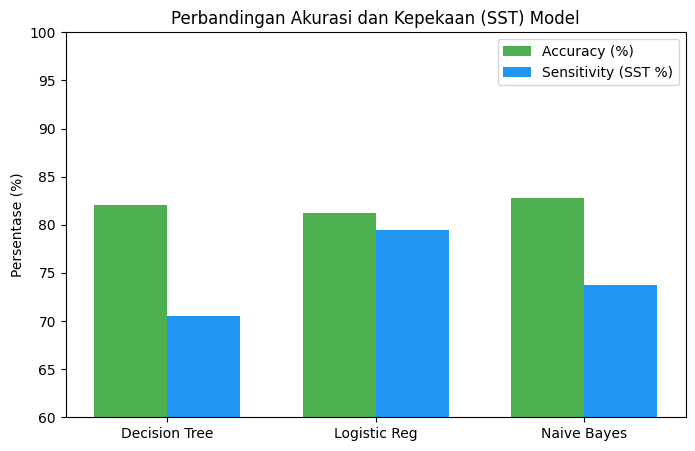

In [9]:
models = ['Decision Tree', 'Logistic Reg', 'Naive Bayes']
accuracy = [82.09, 81.19, 82.74]
sst = [70.53, 79.45, 73.72]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, accuracy, width, label='Accuracy (%)', color='#4CAF50')
rects2 = ax.bar(x + width/2, sst, width, label='Sensitivity (SST %)', color='#2196F3')

ax.set_ylabel('Persentase (%)')
ax.set_title('Perbandingan Akurasi dan Kepekaan (SST) Model')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(60, 100)
ax.legend()

In [10]:
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>


Memproses Peta...


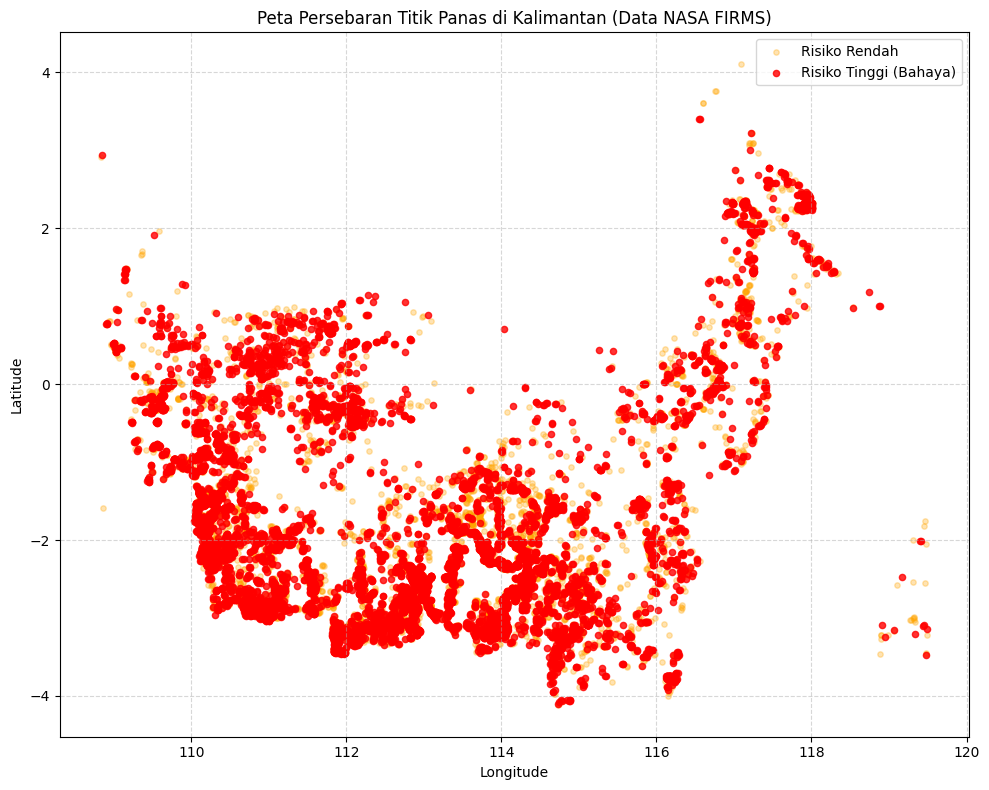

In [12]:
print("\nMemproses Peta...")
df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')

# Filter Kalimantan & Kepercayaan Tinggi
df_kalimantan = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kalimantan = df_kalimantan[df_kalimantan['confidence'] >= 80].copy()

# Label Risiko
df_kalimantan['target_risk'] = np.where(df_kalimantan['frp'] > 30, 1, 0)

plt.figure(figsize=(10, 8))

# Plot Risiko Rendah (Oranye)
plt.scatter(df_kalimantan[df_kalimantan['target_risk']==0]['longitude'],
            df_kalimantan[df_kalimantan['target_risk']==0]['latitude'],
            c='orange', label='Risiko Rendah', alpha=0.3, s=15)

# Plot Risiko Tinggi (Merah)
plt.scatter(df_kalimantan[df_kalimantan['target_risk']==1]['longitude'],
            df_kalimantan[df_kalimantan['target_risk']==1]['latitude'],
            c='red', label='Risiko Tinggi (Bahaya)', alpha=0.8, s=20)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Peta Persebaran Titik Panas di Kalimantan (Data NASA FIRMS)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

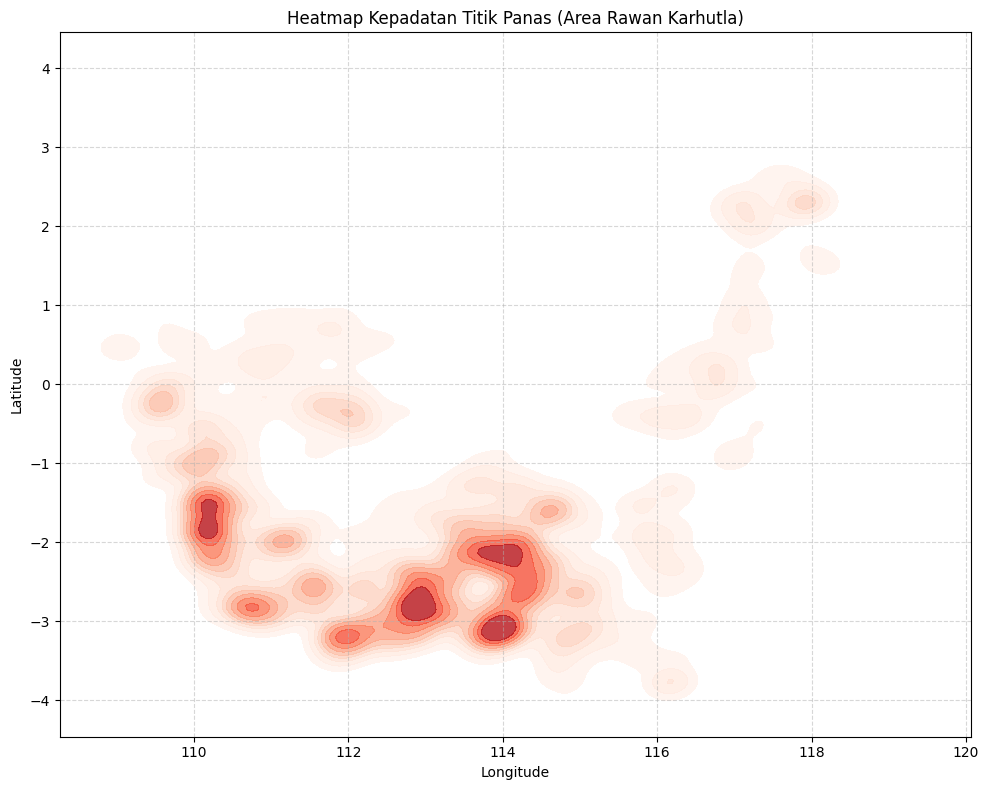

In [15]:
# Load & Filter Data
df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')
df_kal = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kal = df_kal[df_kal['confidence'] >= 80].copy()

# Ensure datetime format
df_kal['acq_date'] = pd.to_datetime(df_kal['acq_date'])

# 1. 2D Density Map (Heatmap) for Vulnerable Areas
plt.figure(figsize=(10, 8))
sns.kdeplot(
    x=df_kal['longitude'],
    y=df_kal['latitude'],
    cmap="Reds",
    fill=True,
    bw_adjust=0.5,
    alpha=0.8
)
plt.title('Heatmap Kepadatan Titik Panas (Area Rawan Karhutla)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

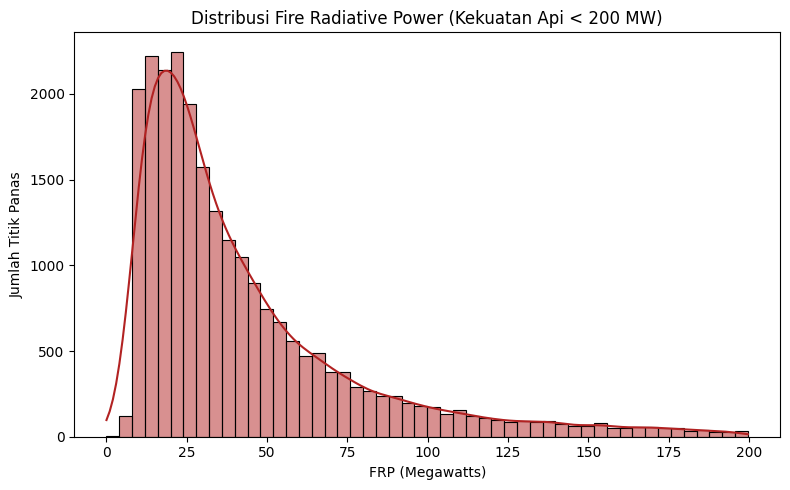

In [16]:
# 2. Distribusi FRP (Kekuatan Api)
plt.figure(figsize=(8, 5))
sns.histplot(df_kal[df_kal['frp'] < 200]['frp'], bins=50, color='firebrick', kde=True)
plt.title('Distribusi Fire Radiative Power (Kekuatan Api < 200 MW)')
plt.xlabel('FRP (Megawatts)')
plt.ylabel('Jumlah Titik Panas')
plt.tight_layout()
plt.show()

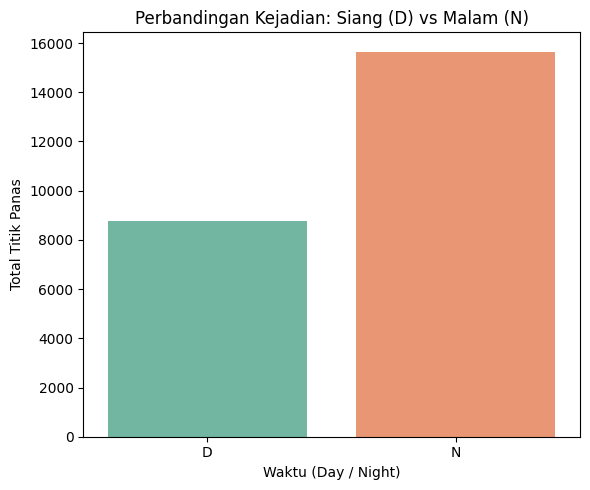

In [17]:
# 3. Waktu Kejadian (Siang vs Malam)
plt.figure(figsize=(6, 5))
sns.countplot(data=df_kal, x='daynight', palette='Set2')
plt.title('Perbandingan Kejadian: Siang (D) vs Malam (N)')
plt.xlabel('Waktu (Day / Night)')
plt.ylabel('Total Titik Panas')
plt.tight_layout()
plt.show()

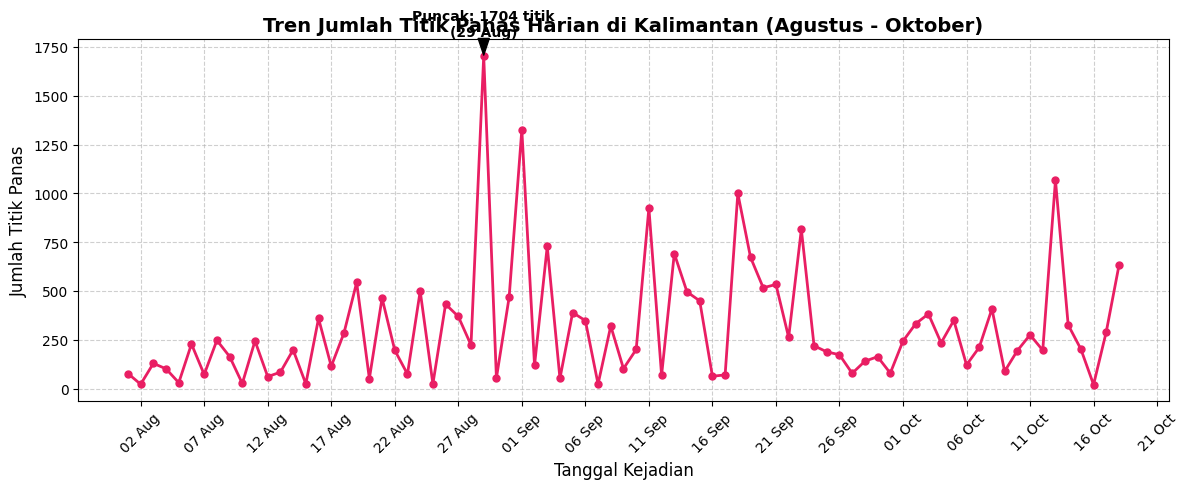

In [20]:
# 1. Load Data dan Filter
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')

# Filter khusus Kalimantan dan Confidence >= 80
df_kal = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kal = df_kal[df_kal['confidence'] >= 80].copy()

# 2. Mengubah kolom tanggal menjadi format Datetime
df_kal['acq_date'] = pd.to_datetime(df_kal['acq_date'])

# 3. Menghitung jumlah titik panas per hari
tren_harian = df_kal.groupby('acq_date').size().reset_index(name='jumlah_titik')

# 4. Membuat Visualisasi Line Chart
plt.figure(figsize=(12, 5))
plt.plot(tren_harian['acq_date'], tren_harian['jumlah_titik'],
         marker='o', color='#E91E63', linewidth=2, markersize=5)

# Mempercantik tampilan grafik
plt.title('Tren Jumlah Titik Panas Harian di Kalimantan (Agustus - Oktober)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal Kejadian', fontsize=12)
plt.ylabel('Jumlah Titik Panas', fontsize=12)

# Mengatur format tanggal di sumbu X agar mudah dibaca
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=5)) # Tampilkan tanggal setiap 5 hari sekali
plt.xticks(rotation=45)

# Menambahkan grid agar angka mudah dilihat
plt.grid(True, linestyle='--', alpha=0.6)

# Menandai titik tertinggi (Puncak Kebakaran)
max_idx = tren_harian['jumlah_titik'].idxmax()
max_date = tren_harian['acq_date'].iloc[max_idx]
max_val = tren_harian['jumlah_titik'].iloc[max_idx]

plt.annotate(f'Puncak: {max_val} titik\n({max_date.strftime("%d %b")})',
             xy=(max_date, max_val),
             xytext=(max_date, max_val + 100),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             ha='center', fontsize=10, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import mean_squared_error, roc_curve, auc
import warnings
warnings.filterwarnings('ignore')

In [22]:
# 1. Load Data
df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')
df_kal = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kal = df_kal[df_kal['confidence'] >= 80].copy()

# Mengambil sampel data kecil agar grafiknya mirip dengan jurnal (80 train + 34 val = 114)
df_sample = df_kal.sample(n=114, random_state=42)
df_sample['target_risk'] = np.where(df_sample['frp'] > 30, 1, 0)

X = df_sample[['latitude', 'longitude', 'brightness', 'confidence']]
y = df_sample['target_risk']

# Split 80 data latih, 34 data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=34, random_state=42)

models = {
    'DT': DecisionTreeClassifier(max_depth=5, random_state=42),
    'MLR': LogisticRegression(max_iter=1000, random_state=42),
    'NB': GaussianNB()
}

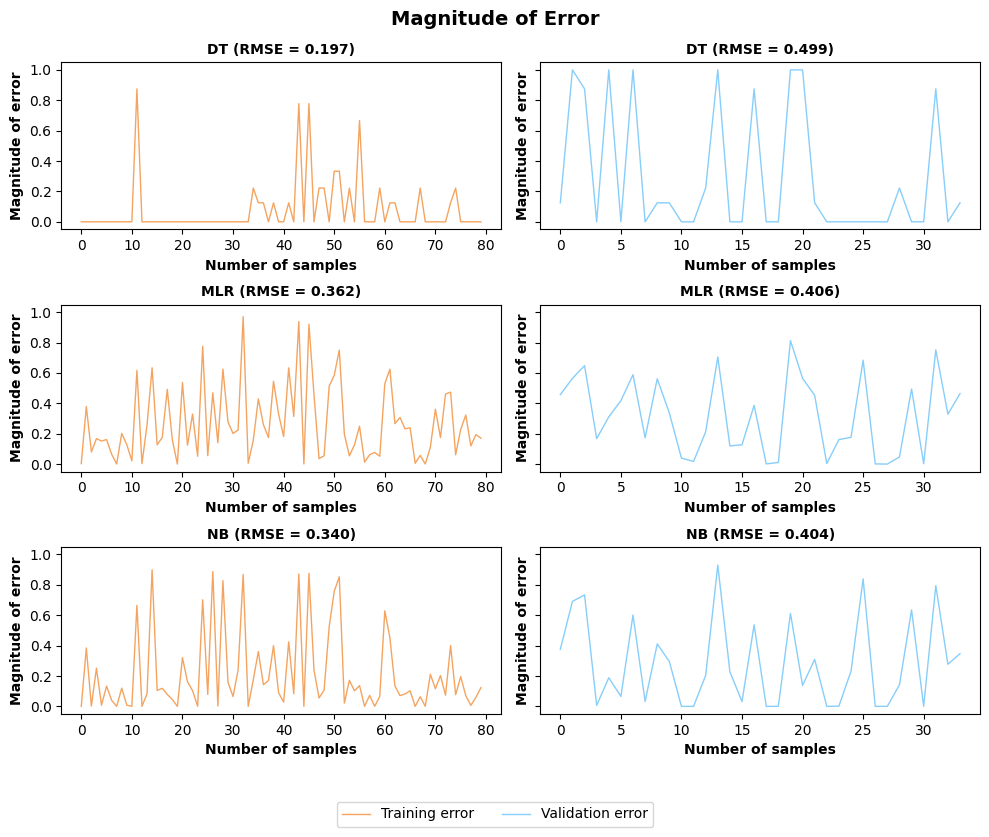

In [23]:
fig1, axes1 = plt.subplots(3, 2, figsize=(10, 8), sharey=True)
fig1.suptitle('Magnitude of Error', fontsize=14, fontweight='bold')

row = 0
for name, model in models.items():
    model.fit(X_train, y_train)

    train_probs = model.predict_proba(X_train)[:, 1]
    test_probs = model.predict_proba(X_test)[:, 1]

    train_error = np.abs(y_train.values - train_probs)
    test_error = np.abs(y_test.values - test_probs)

    rmse_train = np.sqrt(mean_squared_error(y_train, train_probs))
    rmse_test = np.sqrt(mean_squared_error(y_test, test_probs))

    # Kiri: Training
    ax_train = axes1[row, 0]
    ax_train.plot(range(len(train_error)), train_error, color='sandybrown', linewidth=1)
    ax_train.set_title(f'{name} (RMSE = {rmse_train:.3f})', fontsize=10, fontweight='bold')
    ax_train.set_ylabel('Magnitude of error', fontweight='bold')
    ax_train.set_xlabel('Number of samples', fontweight='bold')
    ax_train.set_ylim(-0.05, 1.05)

    # Kanan: Validation
    ax_test = axes1[row, 1]
    ax_test.plot(range(len(test_error)), test_error, color='lightskyblue', linewidth=1)
    ax_test.set_title(f'{name} (RMSE = {rmse_test:.3f})', fontsize=10, fontweight='bold')
    ax_test.set_ylabel('Magnitude of error', fontweight='bold')
    ax_test.set_xlabel('Number of samples', fontweight='bold')
    ax_test.set_ylim(-0.05, 1.05)

    row += 1

fig1.legend(['Training error', 'Validation error'], loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
plt.show()

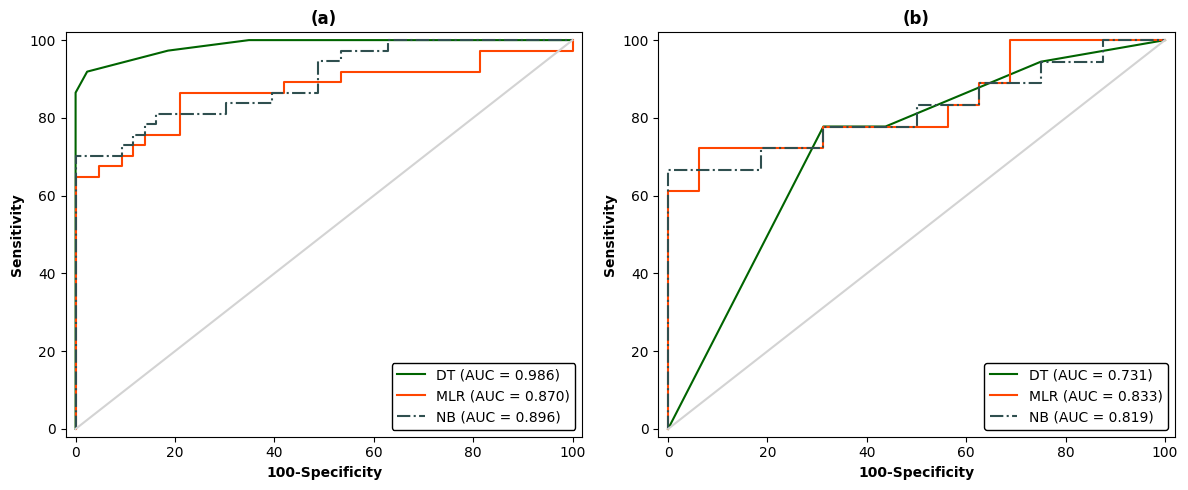

In [24]:
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

colors = {'DT': 'darkgreen', 'MLR': 'orangered', 'NB': 'darkslategray'}
linestyles = {'DT': '-', 'MLR': '-', 'NB': '-.'}

for name, model in models.items():
    # Training ROC
    train_probs = model.predict_proba(X_train)[:, 1]
    fpr_train, tpr_train, _ = roc_curve(y_train, train_probs)
    roc_auc_train = auc(fpr_train, tpr_train)

    ax1.plot(fpr_train * 100, tpr_train * 100,
             color=colors[name], linestyle=linestyles[name],
             label=f'{name} (AUC = {roc_auc_train:.3f})')

    # Validation ROC
    test_probs = model.predict_proba(X_test)[:, 1]
    fpr_test, tpr_test, _ = roc_curve(y_test, test_probs)
    roc_auc_test = auc(fpr_test, tpr_test)

    ax2.plot(fpr_test * 100, tpr_test * 100,
             color=colors[name], linestyle=linestyles[name],
             label=f'{name} (AUC = {roc_auc_test:.3f})')

# Garis diagonal
ax1.plot([0, 100], [0, 100], color='lightgray', linestyle='-')
ax2.plot([0, 100], [0, 100], color='lightgray', linestyle='-')

# Format ax1 (Training)
ax1.set_title('(a)', fontweight='bold')
ax1.set_xlabel('100-Specificity', fontweight='bold')
ax1.set_ylabel('Sensitivity', fontweight='bold')
ax1.set_xlim([-2, 102])
ax1.set_ylim([-2, 102])
ax1.legend(loc="lower right", framealpha=1, edgecolor='black')

# Format ax2 (Validation)
ax2.set_title('(b)', fontweight='bold')
ax2.set_xlabel('100-Specificity', fontweight='bold')
ax2.set_ylabel('Sensitivity', fontweight='bold')
ax2.set_xlim([-2, 102])
ax2.set_ylim([-2, 102])
ax2.legend(loc="lower right", framealpha=1, edgecolor='black')

plt.tight_layout()
plt.show()

In [27]:
import joblib
import pandas as pd

In [28]:
print("Memuat model yang sudah disimpan...")
# 1. Load Model .pkl (Anggap ini adalah server backend Vercel yang sedang menyala)
model_tersimpan = joblib.load('model_karhutla_NB.pkl')

Memuat model yang sudah disimpan...


In [29]:
# 2. Membuat fungsi simulasi API Backend
def prediksi_karhutla_dari_user(lat, lon, brightness, confidence):
    # Menyusun data dari user menjadi format tabel yang dikenali model
    input_user = pd.DataFrame({
        'latitude': [lat],
        'longitude': [lon],
        'brightness': [brightness],
        'confidence': [confidence]
    })

    # Meminta model menebak (0 = Rendah, 1 = Tinggi)
    tebakan = model_tersimpan.predict(input_user)[0]

    # Melihat seberapa yakin model dengan tebakannya (Probabilitas)
    probabilitas = model_tersimpan.predict_proba(input_user)[0]

    # 3. Menampilkan Output ke layar (Ini yang akan direturn ke Frontend)
    print("=========================================")
    print("🌍 DATA DARI SENSOR / INPUT USER:")
    print(f" - Titik Koordinat : Lat {lat}, Lon {lon}")
    print(f" - Suhu Titik Api  : {brightness} Kelvin")
    print(f" - Validitas Api   : {confidence} %")
    print("-----------------------------------------")
    print("🤖 HASIL PREDIKSI AI:")

    if tebakan == 1:
        print(" ⚠️ STATUS: RISIKO TINGGI (BAHAYA!)")
        print("    Api diprediksi akan menjadi besar (FRP Tinggi).")
        print(f"    Tingkat Keyakinan AI: {probabilitas[1] * 100:.2f}%")
    else:
        print(" ✅ STATUS: RISIKO RENDAH (AMAN)")
        print("    Api diprediksi kecil atau mudah dipadamkan.")
        print(f"    Tingkat Keyakinan AI: {probabilitas[0] * 100:.2f}%")
    print("=========================================\n")

In [30]:
print("Menguji Skenario 1 (Kondisi Panas Ekstrem di Palangkaraya)...")
prediksi_karhutla_dari_user(
    lat=-2.20,         # Koordinat Palangkaraya
    lon=113.91,
    brightness=350.5,  # Suhu sangat panas (350 Kelvin = ~77 Celcius di satelit)
    confidence=100     # Satelit 100% yakin itu api
)

print("Menguji Skenario 2 (Kondisi Api Kecil di Pontianak)...")
prediksi_karhutla_dari_user(
    lat=-0.02,         # Koordinat Pontianak
    lon=109.33,
    brightness=310.2,  # Suhu lebih rendah
    confidence=82      # Satelit cukup yakin, tapi tidak 100%
)

Menguji Skenario 1 (Kondisi Panas Ekstrem di Palangkaraya)...
🌍 DATA DARI SENSOR / INPUT USER:
 - Titik Koordinat : Lat -2.2, Lon 113.91
 - Suhu Titik Api  : 350.5 Kelvin
 - Validitas Api   : 100 %
-----------------------------------------
🤖 HASIL PREDIKSI AI:
 ⚠️ STATUS: RISIKO TINGGI (BAHAYA!)
    Api diprediksi akan menjadi besar (FRP Tinggi).
    Tingkat Keyakinan AI: 100.00%

Menguji Skenario 2 (Kondisi Api Kecil di Pontianak)...
🌍 DATA DARI SENSOR / INPUT USER:
 - Titik Koordinat : Lat -0.02, Lon 109.33
 - Suhu Titik Api  : 310.2 Kelvin
 - Validitas Api   : 82 %
-----------------------------------------
🤖 HASIL PREDIKSI AI:
 ✅ STATUS: RISIKO RENDAH (AMAN)
    Api diprediksi kecil atau mudah dipadamkan.
    Tingkat Keyakinan AI: 93.87%

